# Experiment 4 — Option 1 on `014845` only

Train half = first 15 GPL windows (≈ 0–18.75 min). Eval half = last 15 windows.

Dictionary built on the **train half** of this file. Spectrogram shows themes (colour) and boundaries (cyan).

```bash
python -m analysis.song_hmm.exp4.run_014845
```

Select kernel **Python (panMP / ensemble)**. Or open `spectrogram_gallery.html`.

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

from analysis.song_hmm.exp4.paths import WORK, GPL_014845
from analysis.song_hmm.exp4.spectrogram import stitch_gpl, plot_themes_on_spectrogram
from analysis.dict_learning.code.cli import load_windows

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

RES = WORK / "results" / "014845"
summary = json.loads((RES / "summary.json").read_text())
eval_data = json.loads((RES / "eval.json").read_text())
n = len(load_windows(GPL_014845, None, 0))
n_train = n // 2
MODEL = "option1_full"
block = eval_data[MODEL]
themes, bounds = block["themes"], block["boundaries"]

In [2]:
rows = [{"model": m, **sc} for m, sc in summary["scores"].items()]
display(pd.DataFrame(rows).set_index("model").round(3))
print("qualitative:", json.dumps(summary.get("qualitative", {}), indent=2))

,recall@5s,precision@5s,recall@10s,precision@10s,f1@10s,recall@30s,precision@30s,false_alarms_per_h,n_pred,n_marks,median_err_s,p90_err_s
model,,,,,,,,,,,,
option1_pair,0.0,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.0,6.0,NaN,NaN
option1_full,0.0,0.000,0.333,0.062,0.105,0.5,0.094,93.000,32.0,6.0,15.208,20.808
option2,1.0,0.162,1.000,0.162,0.279,1.0,0.162,99.414,37.0,6.0,16.888,25.660
B1,1.0,1.000,1.000,1.000,1.000,1.0,1.000,0.000,6.0,6.0,0.000,0.000
B2,1.0,0.054,1.000,0.054,0.102,1.0,0.054,339.932,112.0,6.0,23.948,28.664


qualitative: {
  "option1_pair_n_themes": 2,
  "option1_full_n_themes": 40,
  "option2_n_themes": 38,
  "option2_median_theme_s": 12.49200000000019,
  "option2_frac_themes_lt_30s": 0.7631578947368421,
  "train_n_tokens": 454,
  "eval_n_tokens": 458
}


In [3]:
print(f"{MODEL}: {len(themes)} themes, {len(bounds)} boundaries")
for b in bounds:
    print(f"  boundary @ {b:8.1f} s ({(b-summary['t_mid_s'])/60:5.2f} min into eval)")
tdf = pd.DataFrame(themes)
if len(tdf):
    tdf["dur_s"] = tdf["t1"] - tdf["t0"]
    display(tdf)

option1_full: 40 themes, 32 boundaries
  boundary @   1134.3 s ( 0.16 min into eval)
  boundary @   1143.7 s ( 0.31 min into eval)
  boundary @   1144.9 s ( 0.33 min into eval)
  boundary @   1207.4 s ( 1.37 min into eval)
  boundary @   1242.6 s ( 1.96 min into eval)
  boundary @   1255.3 s ( 2.17 min into eval)
  boundary @   1257.4 s ( 2.21 min into eval)
  boundary @   1258.7 s ( 2.23 min into eval)
  boundary @   1272.1 s ( 2.45 min into eval)
  boundary @   1273.1 s ( 2.47 min into eval)
  boundary @   1334.8 s ( 3.50 min into eval)
  boundary @   1336.1 s ( 3.52 min into eval)
  boundary @   1360.5 s ( 3.92 min into eval)
  boundary @   1368.0 s ( 4.05 min into eval)
  boundary @   1369.2 s ( 4.07 min into eval)
  boundary @   1578.5 s ( 7.56 min into eval)
  boundary @   1587.9 s ( 7.71 min into eval)
  boundary @   1601.1 s ( 7.94 min into eval)
  boundary @   1628.4 s ( 8.39 min into eval)
  boundary @   1636.6 s ( 8.53 min into eval)
  boundary @   1637.6 s ( 8.54 min into e

,theme,t0,t1,n_tokens,dur_s
0,T1,1125.672,1134.312,3,8.640
1,T2,1134.312,1143.720,4,9.408
2,T3,1143.720,1144.872,1,1.152
3,T4,1144.872,1190.856,12,45.984
4,T1,1191.912,1207.392,10,15.480
5,T2,1207.392,1242.624,9,35.232
6,T3,1242.624,1255.296,10,12.672
7,T2,1255.296,1257.408,2,2.112
8,T3,1257.408,1258.656,1,1.248
9,T2,1258.656,1272.096,9,13.440


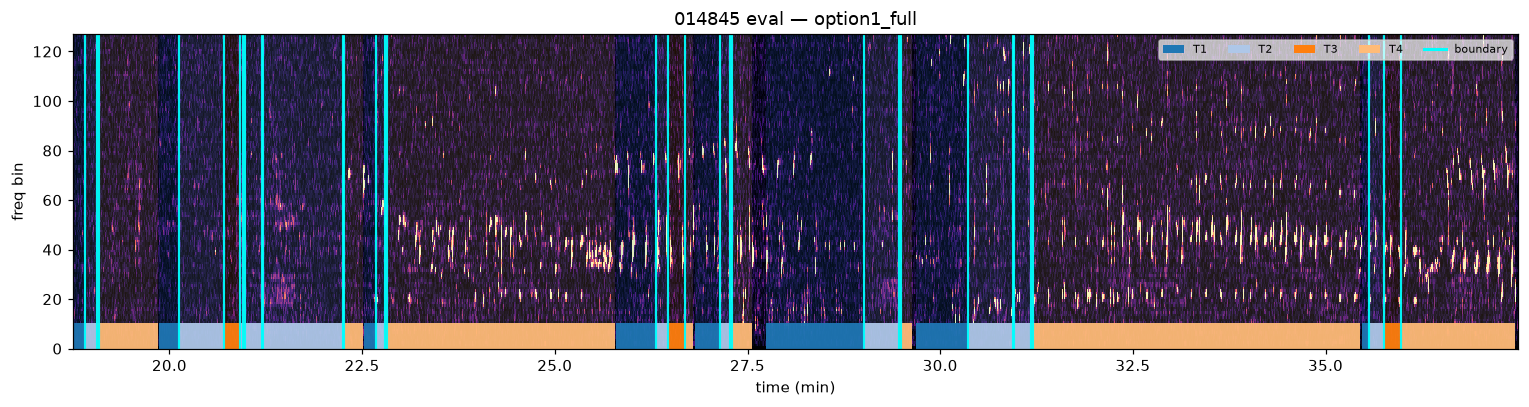

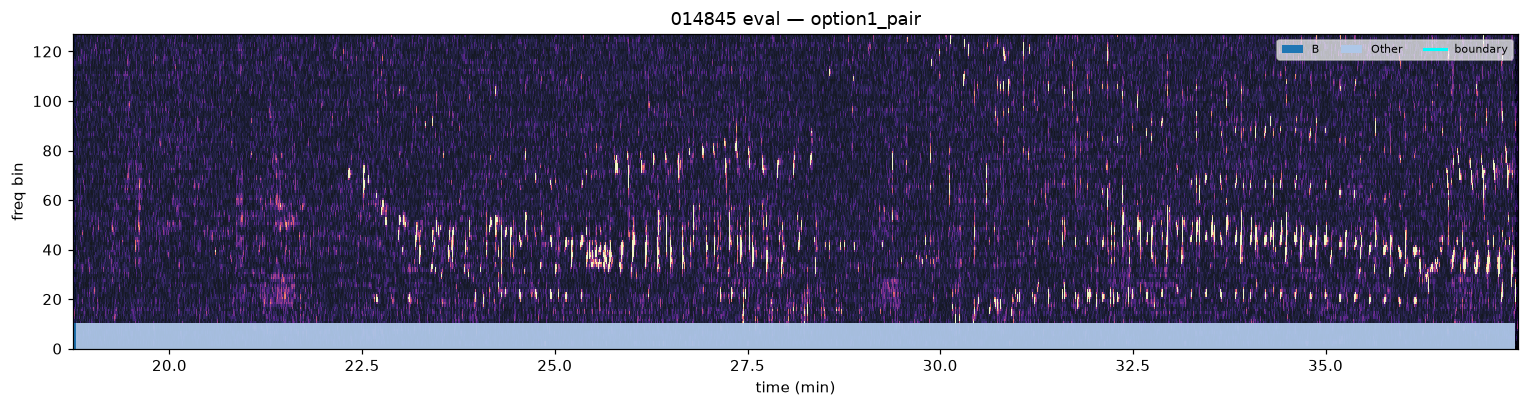

option1_full slice_00.png


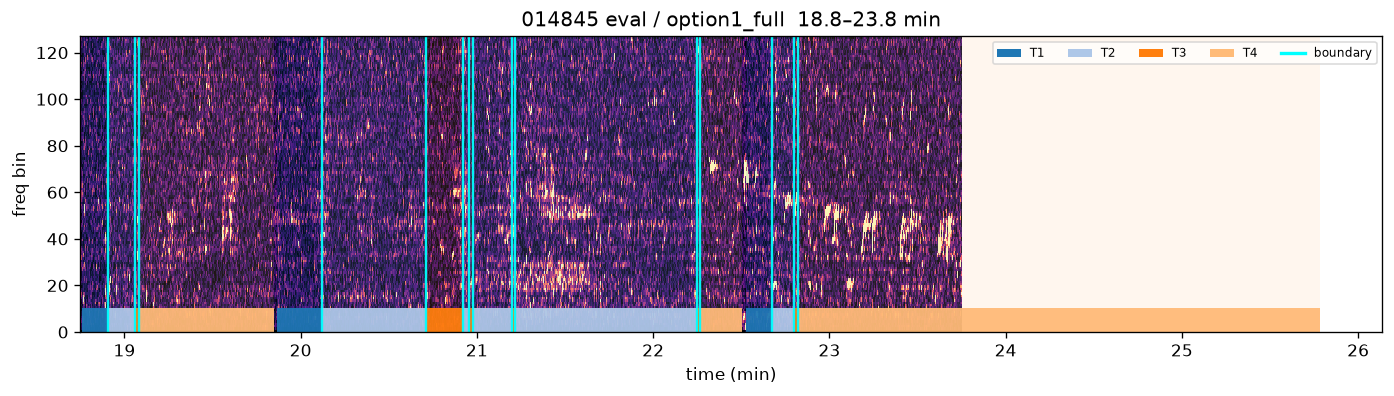

option1_full slice_01.png


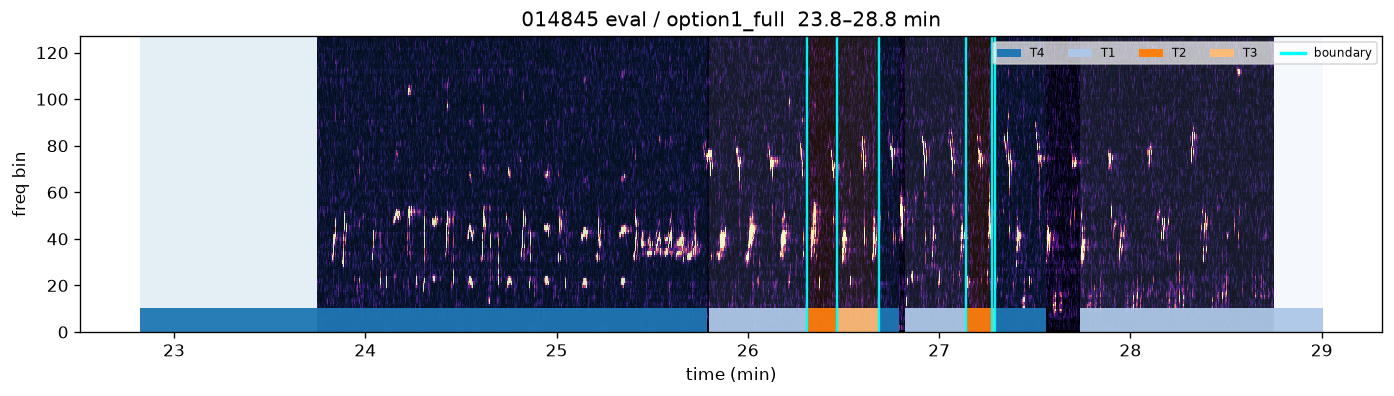

option1_full slice_02.png


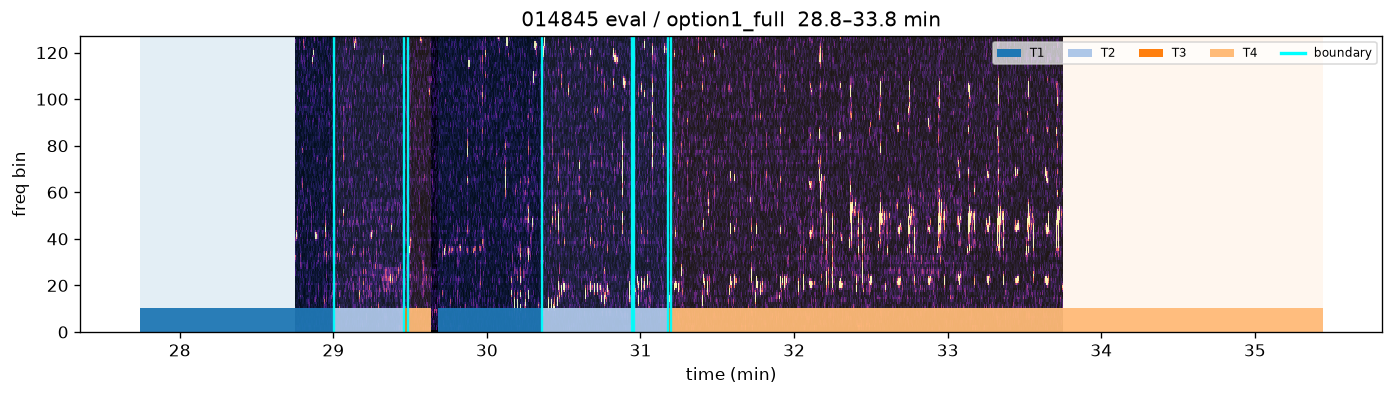

option1_full slice_03.png


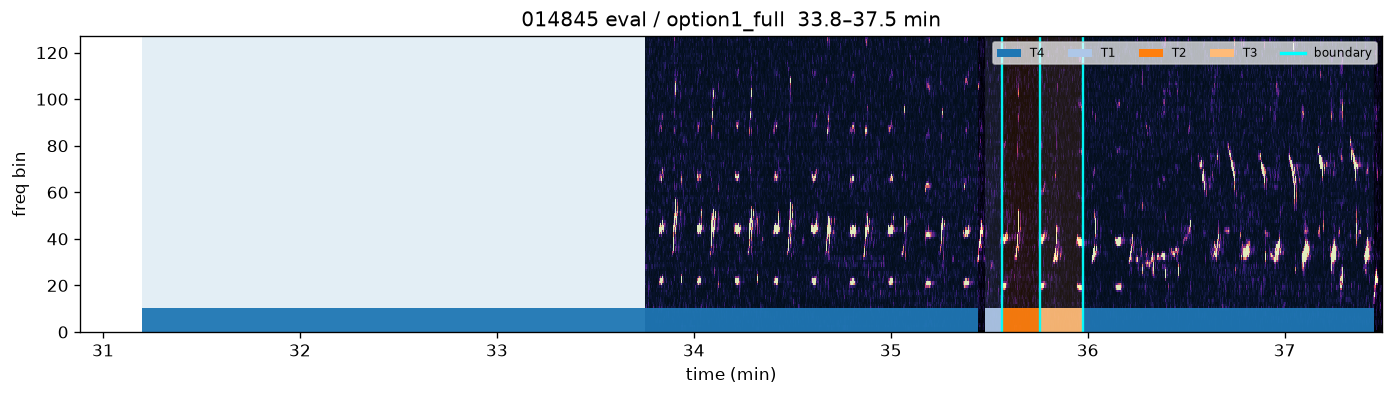

option1_pair slice_00.png


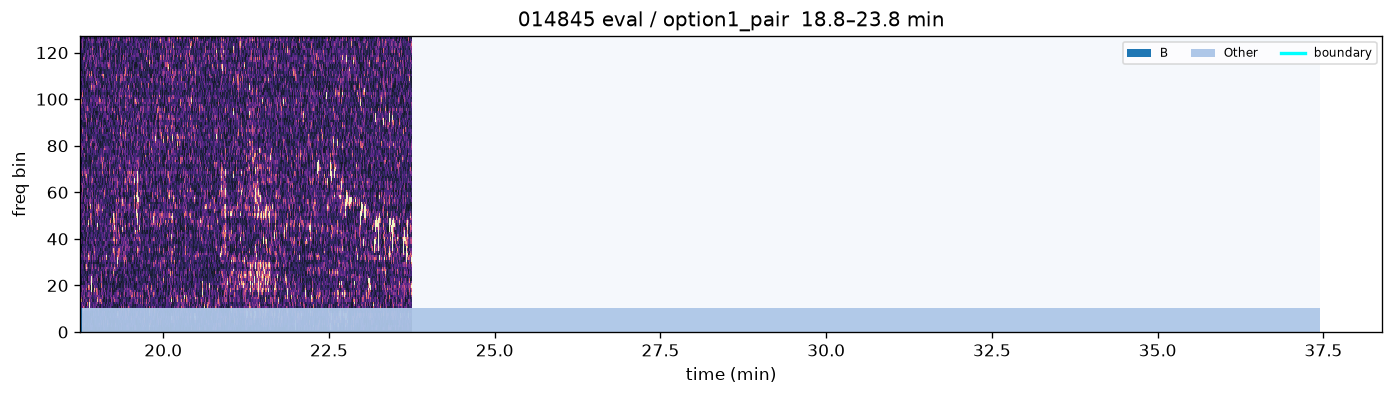

option1_pair slice_01.png


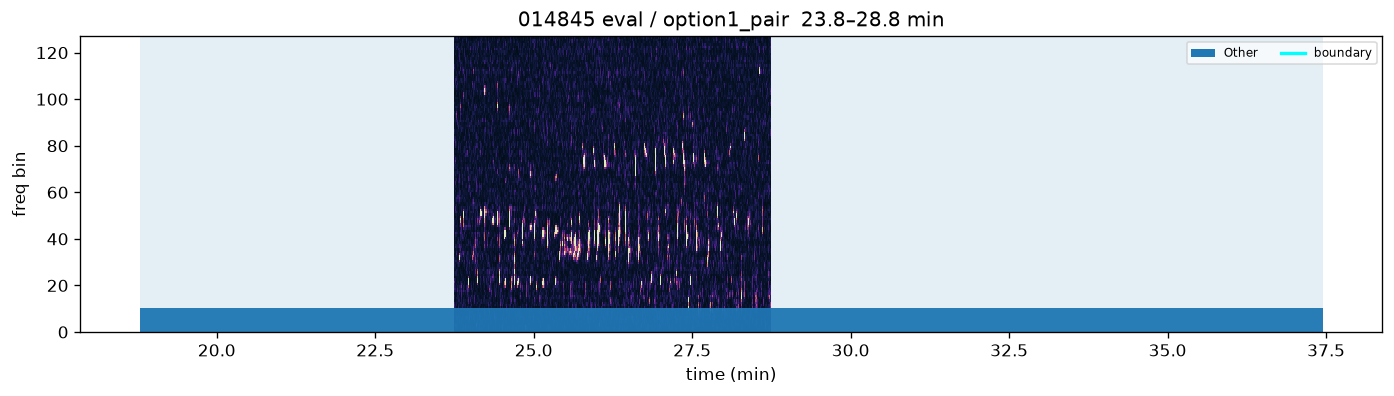

option1_pair slice_02.png


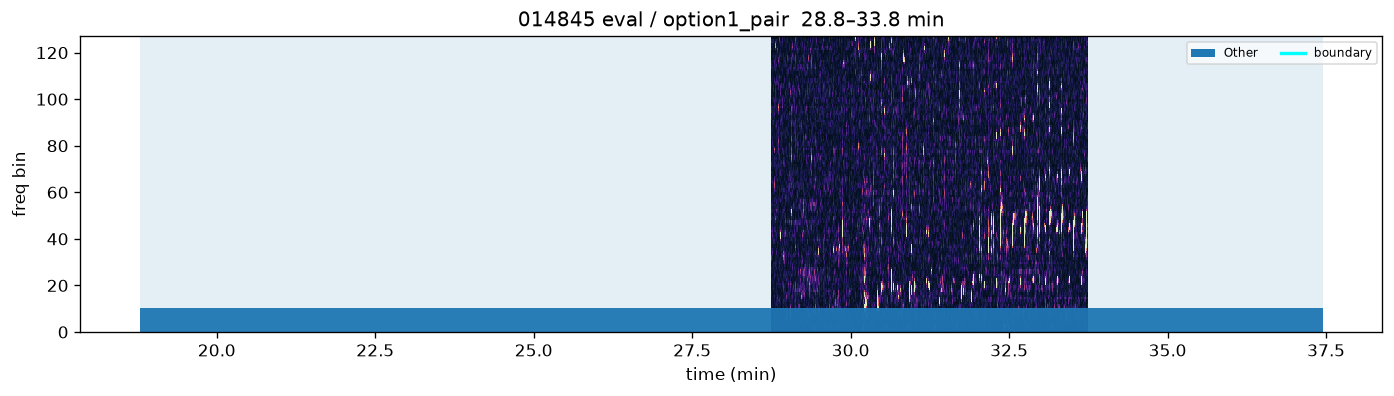

option1_pair slice_03.png


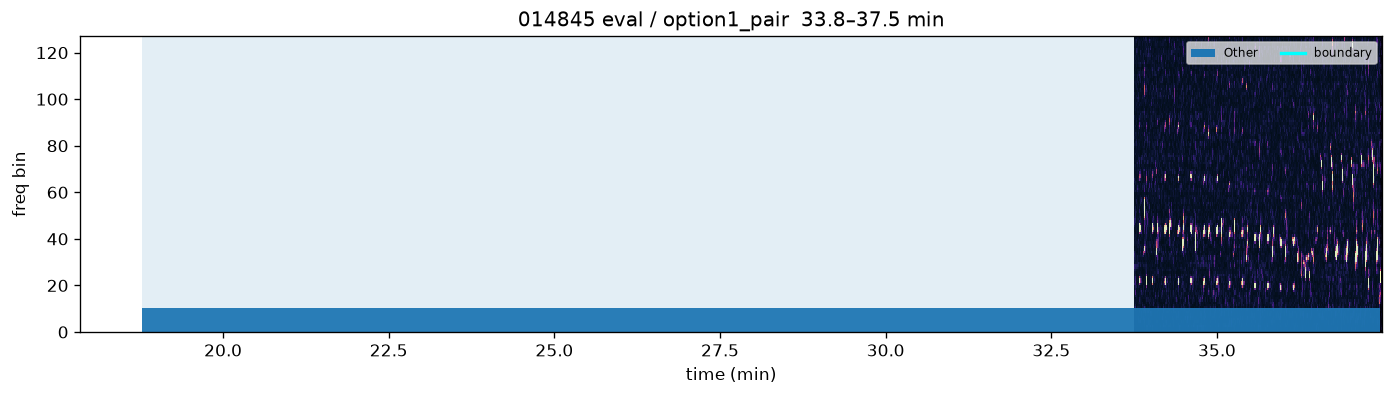

In [4]:
spec, t0, t1, _ = stitch_gpl(GPL_014845, window_offset=n_train, n_windows=n - n_train)
fig, ax = plt.subplots(figsize=(14, 3.8))
plot_themes_on_spectrogram(spec, t0, t1, themes, bounds, title=f"014845 eval — {MODEL}", ax=ax)
plt.tight_layout(); plt.show()

# also pair model
bpair = eval_data["option1_pair"]
fig, ax = plt.subplots(figsize=(14, 3.8))
plot_themes_on_spectrogram(spec, t0, t1, bpair["themes"], bpair["boundaries"], title="014845 eval — option1_pair", ax=ax)
plt.tight_layout(); plt.show()

for model in ("option1_full", "option1_pair"):
    for p in sorted((WORK / "figures" / "014845" / model).glob("slice_*.png")):
        print(model, p.name)
        display(Image(filename=str(p)))